# Results and paper figures

Run the scripts first (see README). This notebook only reads their output.

1. Quick fix: re-analyse the **v1 submission** numbers with the correct paired test.
2. Show the new report.
3. Figures for the paper.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from safety_xai import stats_utils as su
from safety_xai.config import RESULTS_DIR

NAME = "curated"            # which results/<name>/ folder to show
folder = RESULTS_DIR / NAME
COLORS = {"toxic_bert": "#2a78d6", "toxic_roberta": "#eb6834", "SLM": "#1baf7a"}

## 1. v1 submission, re-analysed with a paired test

Each anchor has one synonym and one control version, so we test
d = synonym change - control change per anchor (Wilcoxon signed-rank and a
sign-flip permutation test), instead of the unpaired Mann-Whitney test used in v1.
Note: the v1 Toxic-RoBERTa run scored a different label per phrase, so its numbers
are superseded by the new run.

In [2]:
rows = []
for clf in ["toxic_bert", "toxic_roberta"]:
    v1 = RESULTS_DIR / "v1_submission" / clf
    syn = pd.read_csv(v1 / "synonym_results.csv").set_index("row_index")
    ctrl = pd.read_csv(v1 / "control_results.csv").set_index("row_index")
    common = syn.index.intersection(ctrl.index)
    t = su.paired_test(syn.loc[common, "confidence_delta"], ctrl.loc[common, "confidence_delta"])
    flagged = syn["score_anchor"] >= 0.5
    evaded = flagged & (syn["score_perturbed"] < 0.5)
    rows.append({"classifier": clf, "pairs": t["n"], "anchors flagged (>= 0.5)": int(flagged.sum()),
                 "synonym evaded": int(evaded.sum()), "median d": t["median_diff"],
                 "rank-biserial": t["rank_biserial"], "Wilcoxon p": t["wilcoxon_p"],
                 "permutation p": t["permutation_p"]})
pd.DataFrame(rows)

,classifier,pairs,anchors flagged (>= 0.5),synonym evaded,median d,rank-biserial,Wilcoxon p,permutation p
0,toxic_bert,50,37,31,-0.148373,-0.720784,0.000002,0.00005
1,toxic_roberta,50,38,29,-0.114713,-0.659608,0.000021,0.00005


## 2. The new report

In [3]:
display(Markdown((folder / "report.md").read_text(encoding="utf-8")))

# Results for `curated`

## Setup

- Alert rule: sigmoid probability of ONE fixed label >= threshold. Labels: toxic_bert -> `toxic`, toxic_roberta -> `toxicity`.
- toxic_bert: threshold 0.5, Hugging Face commit `4d6c22e74ba2fdd26bc4f7238f50766b045a0d94`, hardware: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel (8 cores, 17.0 GB RAM, GPU: None).
- toxic_roberta: threshold 0.5, Hugging Face commit `36295dd80b422dc49f40052021430dae76241adc`, hardware: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel (8 cores, 17.0 GB RAM, GPU: None).

Valid rows per condition (invalid = automatic gate failed, e.g. no WordNet synonym):

| condition | valid | total |
|---|---|---|
| synonym | 50 | 50 |
| control_filler | 50 | 50 |
| control_filler_random | 50 | 50 |
| control_wordnet | 19 | 50 |
| control_nonrisk | 28 | 50 |

## Pair quality (automatic checks and LLM annotators)

Means per condition:

| condition | words_changed_pct | embedding_cosine | nli_both_ways | perplexity_increase | word_freq_change |
|---|---|---|---|---|---|
| synonym | 27.925 | 0.759 | 0.648 | 0.239 | -0.507 |
| control_filler | 27.925 | 0.483 | 0.051 | 1.998 | -0.534 |
| control_filler_random | 27.925 | 0.549 | 0.066 | 2.207 | -1.293 |
| control_wordnet | 27.899 | 0.728 | 0.738 | 0.871 | -1.241 |
| control_nonrisk | 25.647 | 0.740 | 0.650 | 1.166 | -0.900 |

Agreement between annotators (LLM panel = proxy for human judgment):

| group | question | raters | items | percent_agreement | fleiss_kappa | krippendorff_alpha | alpha_level |
|---|---|---|---|---|---|---|---|
| llm_panel | same_meaning | 3 | 50 | 0.500 | -0.163 | -0.155 | ordinal |
| llm_panel | same_severity | 3 | 50 | 0.040 | -0.240 | -0.269 | ordinal |
| llm_panel | category | 3 | 100 | 0.400 | 0.499 | 0.501 | nominal |
| llm_panel | natural | 3 | 100 | 0.280 | n/a | 0.247 | ordinal |

LLM panel: 34/50 synonym pairs judged 'similar' meaning AND 'same' severity by majority. Mean meaning score 0.827 (1 = similar, 0.5 = ambiguous, 0 = dissimilar).

## H1a: classifiers fail under synonym swaps

### toxic_bert

Anchors flagged at threshold 0.5: **37 / 50**. The other 13 are never flagged, so they cannot be 'evaded'.

Threshold crossings:

| condition | pairs | anchors flagged | evaded (alert -> no alert) | evasion rate | 95% CI | still flagged | newly flagged (no alert -> alert) | mean score change |
|---|---|---|---|---|---|---|---|---|
| synonym | 50 | 37 | 31 | 0.838 | [0.689, 0.923] | 6 | 1 | -0.563 |
| control_filler | 50 | 37 | 36 | 0.973 | [0.862, 0.995] | 1 | 0 | -0.676 |
| control_filler_random | 50 | 37 | 10 | 0.270 | [0.154, 0.430] | 27 | 0 | -0.188 |
| control_wordnet | 19 | 15 | 7 | 0.467 | [0.248, 0.699] | 8 | 1 | -0.270 |
| control_nonrisk | 28 | 20 | 1 | 0.050 | [0.009, 0.236] | 19 | 1 | -0.002 |

Same table at other thresholds (does the result depend on 0.5?):

| threshold | synonym: flagged | synonym: evasion rate | control_filler: evasion rate | control_filler_random: evasion rate | control_wordnet: evasion rate | control_nonrisk: evasion rate |
|---|---|---|---|---|---|---|
| 0.100 | 44 | 0.659 | 0.841 | 0.227 | 0.062 | 0.042 |
| 0.300 | 40 | 0.800 | 0.925 | 0.250 | 0.267 | 0.045 |
| 0.500 | 37 | 0.838 | 0.973 | 0.270 | 0.467 | 0.050 |
| 0.700 | 34 | 0.824 | 0.971 | 0.235 | 0.571 | 0.000 |
| 0.900 | 29 | 0.897 | 1.000 | 0.483 | 0.818 | 0.133 |

Paired test. For every anchor: d = (synonym score change) - (control score change). Negative d = the synonym lowers the score more than the control. Wilcoxon signed-rank and a sign-flip permutation test on the d values; McNemar on evasion among flagged anchors.

| synonym vs | n | median of (syn change - ctrl change) | 95% CI | rank-biserial | Wilcoxon p | permutation p | evaded only syn / only ctrl | McNemar p |
|---|---|---|---|---|---|---|---|---|
| control_filler | 50 | 0.006 | [6.87e-04, 0.067] | 0.645 | 3.29e-05 | 6.50e-04 | 0 / 5 | 0.062 |
| control_filler_random | 50 | -0.388 | [-0.767, -0.032] | -0.702 | 4.79e-06 | 5.00e-05 | 23 / 2 | 1.94e-05 |
| control_wordnet | 19 | -0.381 | [-0.686, -0.046] | -1.000 | 3.81e-06 | 5.00e-05 | 7 / 0 | 0.016 |
| control_nonrisk | 28 | -0.737 | [-0.835, -0.184] | -0.911 | 1.88e-06 | 5.00e-05 | 16 / 0 | 3.05e-05 |

Reading the controls: `control_filler` overwrites the risk word, so a big drop there is CORRECT behaviour. `control_wordnet` and `control_nonrisk` keep the meaning roughly intact; a big gap to them means the model reacts to the specific risk word, not to any change.

Detection of anchors with and without swear words. Generic toxicity models detect abusive LANGUAGE, not harmful INTENT:

| anchors | n | flagged | detection rate | 95% CI |
|---|---|---|---|---|
| with profanity | 34 | 34 | 1.000 | [0.898, 1.000] |
| without profanity | 16 | 3 | 0.188 | [0.066, 0.430] |

Fisher exact p = 1.58e-09

Evasion split by whether the synonym swap removed a swear word:

| flagged synonym pairs | n | evaded | evasion rate | 95% CI |
|---|---|---|---|---|
| swap removed a swear word | 34 | 28 | 0.824 | [0.665, 0.917] |
| no swear word removed | 3 | 3 | 1.000 | [0.438, 1.000] |

Tokenizer check: Spearman between extra sub-word pieces (synonym - anchor) and score change: rho = 0.114, p = 0.432, n = 50. If this is not significant, drop the tokenizer explanation from the paper.

Confound check. OLS of score change on condition (reference: random WordNet synonym at the same positions) plus word-frequency change, extra sub-word pieces and GPT-2 perplexity increase; standard errors clustered by anchor; n = 97. If the synonym coefficient stays negative and significant, the effect is not explained by these confounds.

| term | coefficient | std error | p |
|---|---|---|---|
| Intercept | -0.365 | 0.124 | 0.003 |
| condition[T.control_nonrisk] | 0.300 | 0.077 | 9.89e-05 |
| condition[T.synonym] | -0.247 | 0.114 | 0.030 |
| word_freq_change | -0.122 | 0.068 | 0.073 |
| extra_subwords | -0.032 | 0.038 | 0.398 |
| perplexity_increase | -0.022 | 0.051 | 0.666 |

Only synonym pairs the LLM panel validated: 18/22 flagged anchors evaded (rate 0.818, CI [0.615, 0.927]).

### toxic_roberta

Anchors flagged at threshold 0.5: **36 / 50**. The other 14 are never flagged, so they cannot be 'evaded'.

Threshold crossings:

| condition | pairs | anchors flagged | evaded (alert -> no alert) | evasion rate | 95% CI | still flagged | newly flagged (no alert -> alert) | mean score change |
|---|---|---|---|---|---|---|---|---|
| synonym | 50 | 36 | 30 | 0.833 | [0.681, 0.921] | 6 | 1 | -0.518 |
| control_filler | 50 | 36 | 32 | 0.889 | [0.747, 0.956] | 4 | 0 | -0.607 |
| control_filler_random | 50 | 36 | 9 | 0.250 | [0.138, 0.411] | 27 | 0 | -0.163 |
| control_wordnet | 19 | 14 | 4 | 0.286 | [0.117, 0.546] | 10 | 0 | -0.220 |
| control_nonrisk | 28 | 19 | 1 | 0.053 | [0.009, 0.246] | 18 | 0 | -0.010 |

Same table at other thresholds (does the result depend on 0.5?):

| threshold | synonym: flagged | synonym: evasion rate | control_filler: evasion rate | control_filler_random: evasion rate | control_wordnet: evasion rate | control_nonrisk: evasion rate |
|---|---|---|---|---|---|---|
| 0.100 | 38 | 0.632 | 0.789 | 0.211 | 0.286 | 0.000 |
| 0.300 | 37 | 0.784 | 0.892 | 0.270 | 0.286 | 0.053 |
| 0.500 | 36 | 0.833 | 0.889 | 0.250 | 0.286 | 0.053 |
| 0.700 | 32 | 0.812 | 0.969 | 0.188 | 0.385 | 0.000 |
| 0.900 | 30 | 0.900 | 0.967 | 0.200 | 0.417 | 0.000 |

Paired test. For every anchor: d = (synonym score change) - (control score change). Negative d = the synonym lowers the score more than the control. Wilcoxon signed-rank and a sign-flip permutation test on the d values; McNemar on evasion among flagged anchors.

| synonym vs | n | median of (syn change - ctrl change) | 95% CI | rank-biserial | Wilcoxon p | permutation p | evaded only syn / only ctrl | McNemar p |
|---|---|---|---|---|---|---|---|---|
| control_filler | 50 | 6.17e-04 | [1.28e-06, 0.004] | 0.468 | 0.003 | 0.004 | 1 / 3 | 0.625 |
| control_filler_random | 50 | -0.034 | [-0.741, -0.001] | -0.656 | 2.31e-05 | 5.00e-05 | 22 / 1 | 5.72e-06 |
| control_wordnet | 19 | -0.106 | [-0.655, -0.034] | -0.779 | 0.002 | 0.001 | 8 / 0 | 0.008 |
| control_nonrisk | 28 | -0.555 | [-0.878, -0.070] | -0.887 | 4.77e-06 | 1.50e-04 | 15 / 0 | 6.10e-05 |

Reading the controls: `control_filler` overwrites the risk word, so a big drop there is CORRECT behaviour. `control_wordnet` and `control_nonrisk` keep the meaning roughly intact; a big gap to them means the model reacts to the specific risk word, not to any change.

Detection of anchors with and without swear words. Generic toxicity models detect abusive LANGUAGE, not harmful INTENT:

| anchors | n | flagged | detection rate | 95% CI |
|---|---|---|---|---|
| with profanity | 34 | 32 | 0.941 | [0.809, 0.984] |
| without profanity | 16 | 4 | 0.250 | [0.102, 0.495] |

Fisher exact p = 1.11e-06

Evasion split by whether the synonym swap removed a swear word:

| flagged synonym pairs | n | evaded | evasion rate | 95% CI |
|---|---|---|---|---|
| swap removed a swear word | 32 | 26 | 0.812 | [0.647, 0.911] |
| no swear word removed | 4 | 4 | 1.000 | [0.510, 1.000] |

Tokenizer check: Spearman between extra sub-word pieces (synonym - anchor) and score change: rho = 0.104, p = 0.474, n = 50. If this is not significant, drop the tokenizer explanation from the paper.

Confound check. OLS of score change on condition (reference: random WordNet synonym at the same positions) plus word-frequency change, extra sub-word pieces and GPT-2 perplexity increase; standard errors clustered by anchor; n = 97. If the synonym coefficient stays negative and significant, the effect is not explained by these confounds.

| term | coefficient | std error | p |
|---|---|---|---|
| Intercept | -0.325 | 0.155 | 0.036 |
| condition[T.control_nonrisk] | 0.244 | 0.088 | 0.006 |
| condition[T.synonym] | -0.245 | 0.141 | 0.081 |
| word_freq_change | -0.116 | 0.075 | 0.122 |
| extra_subwords | -0.020 | 0.053 | 0.710 |
| perplexity_increase | -0.018 | 0.065 | 0.781 |

Only synonym pairs the LLM panel validated: 16/20 flagged anchors evaded (rate 0.800, CI [0.584, 0.919]).

## H1b: XAI explanations become unstable

Explanation failure (defined before looking at results): the swapped risk word is in the top 30% of attributions (ranked towards the alert) for the anchor, but NOT for the synonym version. Stability is split by whether the alert flipped: when it flips, a smaller attribution may simply be a faithful explanation of a smaller score; true fragility is change while the decision stays the same.

### toxic_bert

| method | condition | subset | n | Pearson mean | Pearson sd | Spearman mean | Spearman sd | top-30% overlap | risk word in top-k (anchor) | risk word in top-k (perturbed) | chance level | explanation failures | failure rate |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ig | synonym | all | 50 | 0.344 | 0.384 | 0.435 | 0.362 | 0.602 | 1.000 | 0.580 | 0.350 | 21/50 | 0.420 |
| ig | synonym | alert unchanged | 18 | 0.526 | 0.441 | 0.575 | 0.384 | 0.727 | 1.000 | 0.667 | 0.362 | 6/18 | 0.333 |
| ig | synonym | alert flipped | 32 | 0.242 | 0.310 | 0.356 | 0.329 | 0.531 | 1.000 | 0.531 | 0.344 | 15/32 | 0.469 |
| ig | control_wordnet | all | 19 | 0.785 | 0.273 | 0.629 | 0.232 | 0.754 | 1.000 | 0.947 | 0.352 | 1/19 | 0.053 |
| ig | control_wordnet | alert unchanged | 11 | 0.928 | 0.144 | 0.654 | 0.193 | 0.788 | 1.000 | 1.000 | 0.356 | 0/11 | 0.000 |
| ig | control_wordnet | alert flipped | 8 | 0.589 | 0.293 | 0.595 | 0.288 | 0.708 | 1.000 | 0.875 | 0.347 | 1/8 | 0.125 |
| ig | control_nonrisk | all | 28 | 0.921 | 0.160 | 0.686 | 0.241 | 0.771 | 1.000 | 0.929 | 0.345 | 2/28 | 0.071 |
| ig | control_nonrisk | alert unchanged | 26 | 0.939 | 0.135 | 0.683 | 0.240 | 0.766 | 1.000 | 0.962 | 0.347 | 1/26 | 0.038 |
| ig | control_nonrisk | alert flipped | 2 | 0.690 | 0.342 | 0.730 | 0.348 | 0.833 | 1.000 | 0.500 | 0.317 | 1/2 | 0.500 |
| shap | synonym | all | 50 | 0.258 | 0.450 | 0.533 | 0.287 | 0.577 | 0.980 | 0.420 | 0.350 | 28/49 | 0.571 |
| shap | synonym | alert unchanged | 18 | 0.573 | 0.367 | 0.586 | 0.316 | 0.579 | 0.944 | 0.556 | 0.362 | 7/17 | 0.412 |
| shap | synonym | alert flipped | 32 | 0.081 | 0.396 | 0.503 | 0.270 | 0.576 | 1.000 | 0.344 | 0.344 | 21/32 | 0.656 |
| shap | control_wordnet | all | 19 | 0.724 | 0.365 | 0.697 | 0.224 | 0.684 | 1.000 | 0.842 | 0.352 | 3/19 | 0.158 |
| shap | control_wordnet | alert unchanged | 11 | 0.940 | 0.096 | 0.710 | 0.232 | 0.788 | 1.000 | 1.000 | 0.356 | 0/11 | 0.000 |
| shap | control_wordnet | alert flipped | 8 | 0.426 | 0.393 | 0.679 | 0.228 | 0.542 | 1.000 | 0.625 | 0.347 | 3/8 | 0.375 |
| shap | control_nonrisk | all | 28 | 0.931 | 0.158 | 0.744 | 0.182 | 0.628 | 0.964 | 0.929 | 0.345 | 1/27 | 0.037 |
| shap | control_nonrisk | alert unchanged | 26 | 0.943 | 0.145 | 0.751 | 0.186 | 0.625 | 0.962 | 0.962 | 0.347 | 0/25 | 0.000 |
| shap | control_nonrisk | alert flipped | 2 | 0.768 | 0.293 | 0.655 | 0.077 | 0.667 | 1.000 | 0.500 | 0.317 | 1/2 | 0.500 |
| lime | synonym | all | 50 | 0.264 | 0.462 | 0.593 | 0.274 | 0.627 | 0.920 | 0.340 | 0.350 | 29/46 | 0.630 |
| lime | synonym | alert unchanged | 18 | 0.591 | 0.390 | 0.666 | 0.251 | 0.593 | 0.833 | 0.444 | 0.362 | 7/15 | 0.467 |
| lime | synonym | alert flipped | 32 | 0.079 | 0.396 | 0.551 | 0.282 | 0.646 | 0.969 | 0.281 | 0.344 | 22/31 | 0.710 |
| lime | control_wordnet | all | 19 | 0.665 | 0.437 | 0.755 | 0.216 | 0.693 | 1.000 | 0.789 | 0.352 | 4/19 | 0.211 |
| lime | control_wordnet | alert unchanged | 11 | 0.945 | 0.075 | 0.839 | 0.158 | 0.727 | 1.000 | 1.000 | 0.356 | 0/11 | 0.000 |
| lime | control_wordnet | alert flipped | 8 | 0.279 | 0.435 | 0.640 | 0.240 | 0.646 | 1.000 | 0.500 | 0.347 | 4/8 | 0.500 |
| lime | control_nonrisk | all | 28 | 0.941 | 0.094 | 0.788 | 0.167 | 0.735 | 0.893 | 0.857 | 0.345 | 1/25 | 0.040 |
| lime | control_nonrisk | alert unchanged | 26 | 0.950 | 0.085 | 0.800 | 0.168 | 0.740 | 0.885 | 0.885 | 0.347 | 0/23 | 0.000 |
| lime | control_nonrisk | alert flipped | 2 | 0.814 | 0.162 | 0.637 | 0.018 | 0.667 | 1.000 | 0.500 | 0.317 | 1/2 | 0.500 |

(Full table for every condition is in summary.json.)

Compared with the noise floor (the same anchor explained with different seeds). Instability only counts where synonym-pair agreement is clearly below this floor:

| method | subset | n | same-text Spearman (noise floor) | synonym-pair Spearman | share of pairs below floor | Wilcoxon p |
|---|---|---|---|---|---|---|
| ig | all | 50 | 1.000 | 0.435 | 1.000 | 7.54e-10 |
| ig | alert unchanged | 18 | 1.000 | 0.575 | 1.000 | 1.95e-04 |
| shap | all | 50 | 1.000 | 0.533 | 0.980 | 1.11e-09 |
| shap | alert unchanged | 18 | 1.000 | 0.586 | 0.944 | 2.92e-04 |
| lime | all | 50 | 0.952 | 0.593 | 0.920 | 3.61e-12 |
| lime | alert unchanged | 18 | 0.967 | 0.666 | 0.944 | 1.53e-05 |

IG completeness check: mean |sum of attributions - (F(input) - F(baseline))| = 0.007, mean |Captum convergence delta| = 0.007. IG explains the sigmoid probability with a PAD baseline. Positive and negative attributions add up to the score difference, so one large segment next to negative ones is not a contradiction; it can mislead a moderator who reads the chart without the overall score.

### toxic_roberta

| method | condition | subset | n | Pearson mean | Pearson sd | Spearman mean | Spearman sd | top-30% overlap | risk word in top-k (anchor) | risk word in top-k (perturbed) | chance level | explanation failures | failure rate |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ig | synonym | all | 50 | 0.279 | 0.453 | 0.345 | 0.387 | 0.518 | 1.000 | 0.460 | 0.350 | 27/50 | 0.540 |
| ig | synonym | alert unchanged | 19 | 0.588 | 0.364 | 0.592 | 0.250 | 0.596 | 1.000 | 0.474 | 0.351 | 10/19 | 0.526 |
| ig | synonym | alert flipped | 31 | 0.089 | 0.397 | 0.194 | 0.381 | 0.470 | 1.000 | 0.452 | 0.350 | 17/31 | 0.548 |
| ig | control_wordnet | all | 19 | 0.593 | 0.492 | 0.476 | 0.375 | 0.623 | 1.000 | 0.737 | 0.352 | 5/19 | 0.263 |
| ig | control_wordnet | alert unchanged | 15 | 0.783 | 0.281 | 0.641 | 0.204 | 0.644 | 1.000 | 0.867 | 0.360 | 2/15 | 0.133 |
| ig | control_wordnet | alert flipped | 4 | -0.118 | 0.481 | -0.140 | 0.096 | 0.542 | 1.000 | 0.250 | 0.325 | 3/4 | 0.750 |
| ig | control_nonrisk | all | 28 | 0.905 | 0.235 | 0.781 | 0.216 | 0.795 | 1.000 | 0.964 | 0.345 | 1/28 | 0.036 |
| ig | control_nonrisk | alert unchanged | 27 | 0.904 | 0.240 | 0.792 | 0.213 | 0.799 | 1.000 | 0.963 | 0.346 | 1/27 | 0.037 |
| ig | control_nonrisk | alert flipped | 1 | 0.950 | n/a | 0.503 | n/a | 0.667 | 1.000 | 1.000 | 0.300 | 0/1 | 0.000 |
| shap | synonym | all | 50 | 0.243 | 0.511 | 0.389 | 0.406 | 0.568 | 0.980 | 0.480 | 0.350 | 25/49 | 0.510 |
| shap | synonym | alert unchanged | 19 | 0.442 | 0.459 | 0.494 | 0.362 | 0.583 | 0.947 | 0.579 | 0.351 | 7/18 | 0.389 |
| shap | synonym | alert flipped | 31 | 0.121 | 0.509 | 0.325 | 0.423 | 0.559 | 1.000 | 0.419 | 0.350 | 18/31 | 0.581 |
| shap | control_wordnet | all | 19 | 0.632 | 0.431 | 0.505 | 0.288 | 0.596 | 1.000 | 0.842 | 0.352 | 3/19 | 0.158 |
| shap | control_wordnet | alert unchanged | 15 | 0.793 | 0.214 | 0.582 | 0.243 | 0.667 | 1.000 | 1.000 | 0.360 | 0/15 | 0.000 |
| shap | control_wordnet | alert flipped | 4 | 0.025 | 0.529 | 0.217 | 0.285 | 0.333 | 1.000 | 0.250 | 0.325 | 3/4 | 0.750 |
| shap | control_nonrisk | all | 28 | 0.910 | 0.289 | 0.722 | 0.292 | 0.804 | 0.964 | 0.929 | 0.345 | 1/27 | 0.037 |
| shap | control_nonrisk | alert unchanged | 27 | 0.909 | 0.295 | 0.719 | 0.297 | 0.796 | 0.963 | 0.926 | 0.346 | 1/26 | 0.038 |
| shap | control_nonrisk | alert flipped | 1 | 0.934 | n/a | 0.794 | n/a | 1.000 | 1.000 | 1.000 | 0.300 | 0/1 | 0.000 |
| lime | synonym | all | 50 | 0.248 | 0.474 | 0.463 | 0.321 | 0.503 | 0.960 | 0.340 | 0.350 | 31/48 | 0.646 |
| lime | synonym | alert unchanged | 19 | 0.561 | 0.385 | 0.606 | 0.322 | 0.553 | 0.947 | 0.474 | 0.351 | 9/18 | 0.500 |
| lime | synonym | alert flipped | 31 | 0.056 | 0.421 | 0.375 | 0.292 | 0.473 | 0.968 | 0.258 | 0.350 | 22/30 | 0.733 |
| lime | control_wordnet | all | 19 | 0.555 | 0.615 | 0.602 | 0.393 | 0.763 | 0.947 | 0.737 | 0.352 | 4/18 | 0.222 |
| lime | control_wordnet | alert unchanged | 15 | 0.772 | 0.354 | 0.671 | 0.364 | 0.778 | 0.933 | 0.867 | 0.360 | 1/14 | 0.071 |
| lime | control_wordnet | alert flipped | 4 | -0.259 | 0.754 | 0.345 | 0.446 | 0.708 | 1.000 | 0.250 | 0.325 | 3/4 | 0.750 |
| lime | control_nonrisk | all | 28 | 0.912 | 0.187 | 0.818 | 0.185 | 0.795 | 0.929 | 0.857 | 0.345 | 2/26 | 0.077 |
| lime | control_nonrisk | alert unchanged | 27 | 0.915 | 0.190 | 0.819 | 0.189 | 0.799 | 0.926 | 0.852 | 0.346 | 2/25 | 0.080 |
| lime | control_nonrisk | alert flipped | 1 | 0.815 | n/a | 0.794 | n/a | 0.667 | 1.000 | 1.000 | 0.300 | 0/1 | 0.000 |

(Full table for every condition is in summary.json.)

Compared with the noise floor (the same anchor explained with different seeds). Instability only counts where synonym-pair agreement is clearly below this floor:

| method | subset | n | same-text Spearman (noise floor) | synonym-pair Spearman | share of pairs below floor | Wilcoxon p |
|---|---|---|---|---|---|---|
| ig | all | 50 | 1.000 | 0.345 | 1.000 | 7.54e-10 |
| ig | alert unchanged | 19 | 1.000 | 0.592 | 1.000 | 1.31e-04 |
| shap | all | 50 | 1.000 | 0.389 | 0.980 | 1.11e-09 |
| shap | alert unchanged | 19 | 1.000 | 0.494 | 0.947 | 1.96e-04 |
| lime | all | 50 | 0.923 | 0.463 | 0.960 | 1.09e-09 |
| lime | alert unchanged | 19 | 0.942 | 0.606 | 0.895 | 3.81e-05 |

IG completeness check: mean |sum of attributions - (F(input) - F(baseline))| = 0.003, mean |Captum convergence delta| = 0.003. IG explains the sigmoid probability with a PAD baseline. Positive and negative attributions add up to the score difference, so one large segment next to negative ones is not a contradiction; it can mislead a moderator who reads the chart without the overall score.

## H1c: does the SLM keep detecting the risk better than the classifier?

One question for every method: **does it still point to the risk after the synonym swap?** Classifier = alert still fires; XAI = swapped risk word still in the top-k attributions; SLM = still labelled harmful (and same category).

| method | pairs | risk identified on anchor | still identified after swap | retention | 95% CI | identified on synonym text (all pairs) |
|---|---|---|---|---|---|---|
| toxic_bert: alert | 50 | 37 | 6 | 0.162 | [0.077, 0.311] | 0.140 |
| toxic_bert: IG risk word in top 30% | 50 | 50 | 29 | 0.580 | [0.442, 0.706] | 0.580 |
| toxic_bert: SHAP risk word in top 30% | 50 | 49 | 21 | 0.429 | [0.300, 0.567] | 0.420 |
| toxic_bert: LIME risk word in top 30% | 50 | 46 | 17 | 0.370 | [0.245, 0.514] | 0.340 |
| toxic_roberta: alert | 50 | 36 | 6 | 0.167 | [0.079, 0.319] | 0.140 |
| toxic_roberta: IG risk word in top 30% | 50 | 50 | 23 | 0.460 | [0.330, 0.596] | 0.460 |
| toxic_roberta: SHAP risk word in top 30% | 50 | 49 | 24 | 0.490 | [0.356, 0.625] | 0.480 |
| toxic_roberta: LIME risk word in top 30% | 50 | 48 | 17 | 0.354 | [0.234, 0.496] | 0.340 |
| SLM: harmful | 50 | 47 | 43 | 0.915 | [0.801, 0.966] | 0.900 |
| SLM: harmful + same category | 50 | 47 | 32 | 0.681 | [0.538, 0.796] | 0.640 |
| SLM narrative names same category (judge, narrative only) | 50 | 39 | 24 | 0.615 | [0.459, 0.751] | 0.480 |

Misses on synonym texts (all harmful), classifier vs SLM, and how many classifier evasions the SLM still catches:

| classifier | pairs | classifier misses | SLM misses | missed only by classifier / only by SLM | McNemar p | classifier evasions | caught by SLM | recovery rate | 95% CI |
|---|---|---|---|---|---|---|---|---|---|
| toxic_bert | 50 | 43 | 5 | 38 / 0 | 7.28e-12 | 31 | 26 | 0.839 | [0.674, 0.929] |
| toxic_roberta | 50 | 43 | 5 | 38 / 0 | 7.28e-12 | 30 | 25 | 0.833 | [0.664, 0.927] |

Alert rates for every group of texts. On harmful texts, 1 - rate = false-negative rate; on benign texts, the rate = false-positive rate. The SLM counts as an alert when it says 'harmful'.

| texts | gold | n | toxic_bert alert rate | toxic_roberta alert rate | SLM harmful rate | SLM unclear rate |
|---|---|---|---|---|---|---|
| anchors | harmful | 50 | 0.740 | 0.720 | 0.940 | 0.000 |
| synonym | harmful | 50 | 0.140 | 0.140 | 0.900 | 0.000 |
| control_filler | unclear (risk word overwritten) | 50 | 0.020 | 0.080 | 0.200 | 0.020 |
| control_filler_random | unclear (may overwrite risk word) | 50 | 0.540 | 0.540 | 0.300 | 0.000 |
| control_wordnet | harmful if the random synonym fits | 19 | 0.474 | 0.526 | 0.789 | 0.000 |
| control_nonrisk | harmful (risk word kept) | 28 | 0.714 | 0.643 | 0.821 | 0.000 |
| single queries: benign | benign | 22 | 0.000 | 0.000 | 0.045 | 0.000 |
| single queries: ambiguous | ambiguous | 18 | 0.000 | 0.000 | 0.222 | 0.000 |

Secondary: how similar are anchor and perturbed narratives? (graph similarity = 1 - GED / total size)

| measure | synonym mean | vs | control mean | n | median diff | Wilcoxon p |
|---|---|---|---|---|---|---|
| graph_similarity | 0.778 | control_filler | 0.683 | 50 | 0.114 | 6.83e-05 |
| graph_similarity | 0.778 | control_filler_random | 0.671 | 50 | 0.112 | 5.15e-05 |
| graph_similarity | 0.769 | control_wordnet | 0.755 | 19 | 0.040 | 0.542 |
| graph_similarity | 0.793 | control_nonrisk | 0.716 | 28 | 0.077 | 0.034 |
| embedding_similarity | 0.794 | control_filler | 0.592 | 50 | 0.175 | 2.12e-09 |
| embedding_similarity | 0.794 | control_filler_random | 0.625 | 50 | 0.206 | 1.28e-06 |
| embedding_similarity | 0.778 | control_wordnet | 0.790 | 19 | 0.038 | 0.953 |
| embedding_similarity | 0.804 | control_nonrisk | 0.748 | 28 | 0.077 | 0.056 |

Offline judge (qwen2.5:7b, local; sees the raw query, never attribution scores). 287 unique narratives, 574 judgements, 0 failed calls (failed calls are excluded).

| texts | narratives judged | faithfulness (1-5) | overstates risk |
|---|---|---|---|
| anchors | 50 | 2.920 | 0.040 |
| synonym | 50 | 2.860 | 0.080 |
| control_filler | 50 | 2.820 | 0.100 |
| control_filler_random | 50 | 2.800 | 0.160 |
| control_wordnet | 19 | 2.789 | 0.053 |
| control_nonrisk | 28 | 2.857 | 0.036 |
| single queries: benign | 22 | 4.045 | 0.000 |
| single queries: ambiguous | 18 | 3.778 | 0.000 |

SLM cost on this machine (Intel64 Family 6 Model 142 Stepping 12, GenuineIntel, 17.0 GB RAM): mean 43.447 s per query (median 37.580, p95 70.047, n = 287). Ollama memory: [{'model': 'llama3:8b', 'total_gb': 5.05, 'gpu_gb': 0.0}].

## Holm-corrected p-values for the primary tests

| test | raw p | Holm p |
|---|---|---|
| H1c toxic_bert: McNemar misses classifier vs SLM | 7.28e-12 | 1.16e-10 |
| H1c toxic_roberta: McNemar misses classifier vs SLM | 7.28e-12 | 1.16e-10 |
| H1a toxic_bert: Wilcoxon syn vs control_nonrisk | 1.88e-06 | 2.64e-05 |
| H1a toxic_bert: Wilcoxon syn vs control_wordnet | 3.81e-06 | 4.96e-05 |
| H1a toxic_roberta: Wilcoxon syn vs control_nonrisk | 4.77e-06 | 5.72e-05 |
| H1a toxic_bert: Wilcoxon syn vs control_filler_random | 4.79e-06 | 5.72e-05 |
| H1b toxic_bert: lime synonym vs noise floor | 1.53e-05 | 1.53e-04 |
| H1a toxic_roberta: Wilcoxon syn vs control_filler_random | 2.31e-05 | 2.08e-04 |
| H1a toxic_bert: Wilcoxon syn vs control_filler | 3.29e-05 | 2.63e-04 |
| H1b toxic_roberta: lime synonym vs noise floor | 3.81e-05 | 2.67e-04 |
| H1b toxic_roberta: ig synonym vs noise floor | 1.31e-04 | 7.89e-04 |
| H1b toxic_bert: ig synonym vs noise floor | 1.95e-04 | 9.74e-04 |
| H1b toxic_roberta: shap synonym vs noise floor | 1.96e-04 | 9.74e-04 |
| H1b toxic_bert: shap synonym vs noise floor | 2.92e-04 | 9.74e-04 |
| H1a toxic_roberta: Wilcoxon syn vs control_wordnet | 0.002 | 0.003 |
| H1a toxic_roberta: Wilcoxon syn vs control_filler | 0.003 | 0.003 |


## 3. Figures

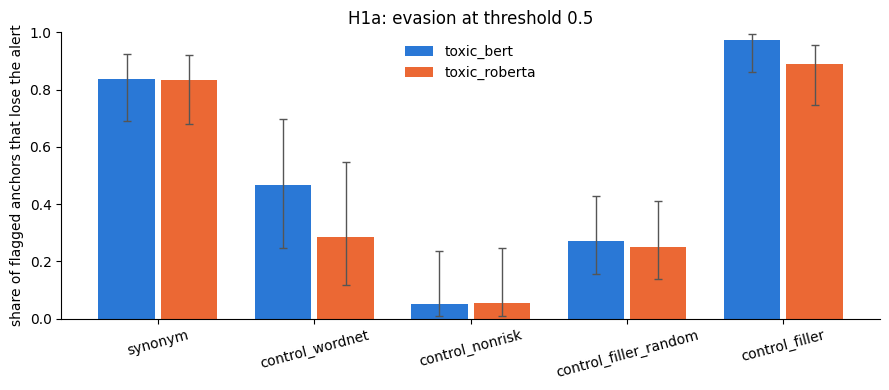

In [4]:
summary = json.loads((folder / "summary.json").read_text())
classifiers = list(summary.get("H1a", {}))

# Figure A: evasion rate per condition (with 95% CI), one bar group per classifier
conditions = ["synonym", "control_wordnet", "control_nonrisk", "control_filler_random", "control_filler"]
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.8 / max(1, len(classifiers))
for i, clf in enumerate(classifiers):
    rates = [summary["H1a"][clf].get(f"evasion_{c}", {}) for c in conditions]
    y = np.array([r.get("rate", np.nan) for r in rates], dtype=float)
    lo = y - np.array([r.get("ci_low", np.nan) for r in rates], dtype=float)
    hi = np.array([r.get("ci_high", np.nan) for r in rates], dtype=float) - y
    x = np.arange(len(conditions)) + i * width
    ax.bar(x, y, width=width - 0.04, color=COLORS[clf], label=clf)
    ax.errorbar(x, y, yerr=[lo, hi], fmt="none", ecolor="#555555", lw=1, capsize=3)
ax.set_xticks(np.arange(len(conditions)) + width * (len(classifiers) - 1) / 2, conditions, rotation=15)
ax.set_ylabel("share of flagged anchors that lose the alert")
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("H1a: evasion at threshold 0.5")
fig.tight_layout()
plt.show()

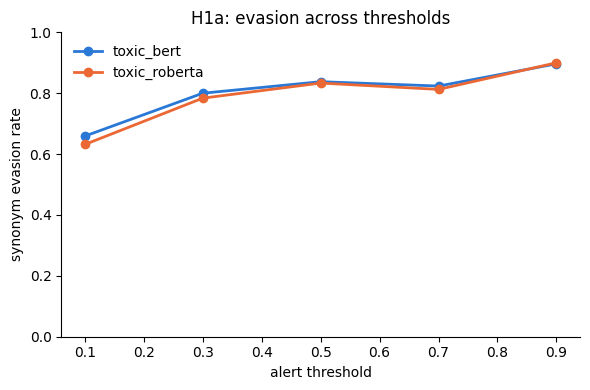

In [5]:
# Figure B: does the result depend on the threshold?
fig, ax = plt.subplots(figsize=(6, 4))
for clf in classifiers:
    sweep = pd.DataFrame(summary["H1a"][clf]["threshold_sweep"])
    ax.plot(sweep["threshold"], sweep["synonym: evasion rate"], marker="o", ms=6, lw=2, color=COLORS[clf], label=clf)
ax.set_xlabel("alert threshold")
ax.set_ylabel("synonym evasion rate")
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("H1a: evasion across thresholds")
fig.tight_layout()
plt.show()

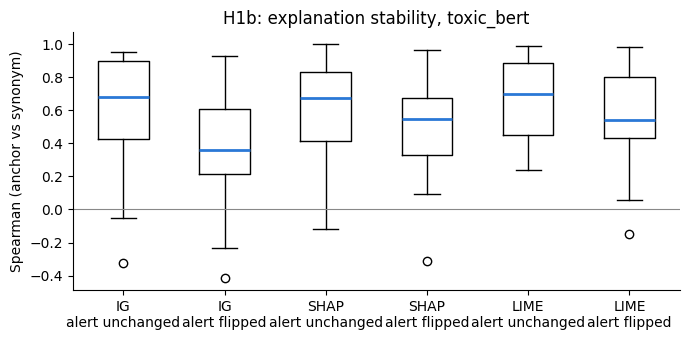

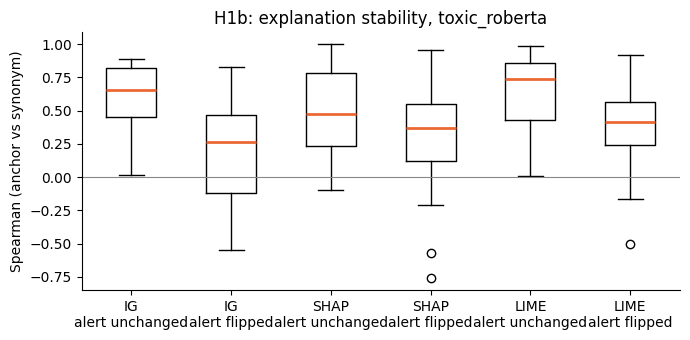

In [6]:
# Figure C: explanation stability (Spearman between anchor and synonym attributions), alert unchanged vs flipped
for clf in classifiers:
    path = folder / clf / "scores.csv"
    if not path.exists():
        continue
    df = pd.read_csv(path)
    syn = df[df["condition"] == "synonym"]
    if "ig_spearman" not in syn:
        continue
    fig, ax = plt.subplots(figsize=(7, 3.5))
    data, labels = [], []
    for m in ["ig", "shap", "lime"]:
        for flipped, name in [(False, "unchanged"), (True, "flipped")]:
            data.append(syn.loc[syn["alert_flipped"] == flipped, f"{m}_spearman"].dropna())
            labels.append(f"{m.upper()}\nalert {name}")
    ax.boxplot(data, tick_labels=labels, widths=0.5, medianprops={"color": COLORS[clf], "lw": 2})
    ax.axhline(0, color="#888888", lw=0.8)
    ax.set_ylabel("Spearman (anchor vs synonym)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"H1b: explanation stability, {clf}")
    fig.tight_layout()
    plt.show()

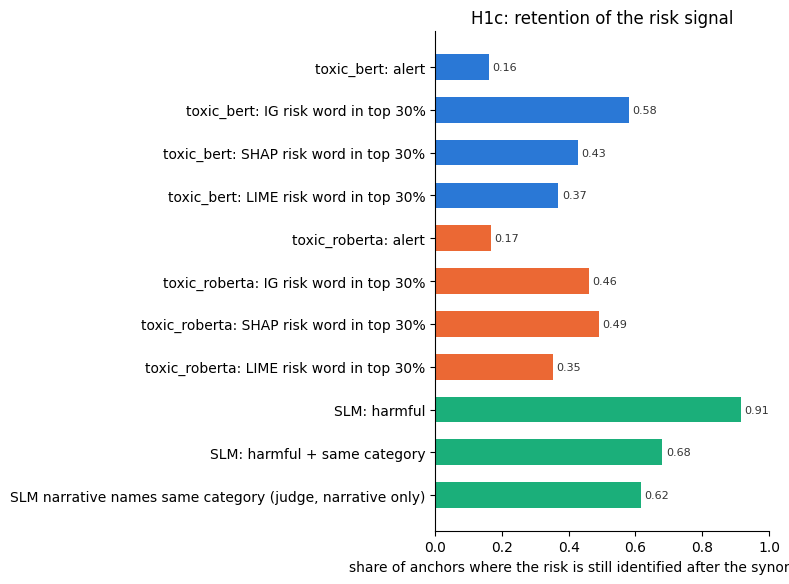

In [7]:
# Figure D: one shared question for every method - is the risk still identified after the swap?
if "H1c" in summary:
    ret = pd.DataFrame(summary["H1c"]["retention"])
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(ret) + 1))
    colors = [COLORS["SLM"] if m.startswith("SLM") else
              COLORS["toxic_roberta"] if m.startswith("toxic_roberta") else COLORS["toxic_bert"] for m in ret["method"]]
    ax.barh(ret["method"], ret["retention"], height=0.6, color=colors)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of anchors where the risk is still identified after the synonym swap")
    ax.spines[["top", "right"]].set_visible(False)
    for y, v in enumerate(ret["retention"]):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color="#333333")
    ax.set_title("H1c: retention of the risk signal")
    fig.tight_layout()
    plt.show()